# Extension 1 — Candidate Price Data (2024-02 → 2026-10)

**Question:** the original mandi files stop on 2024-02-02. Can recent, officially published prices extend the price series honestly, without mixing them into the frozen Phase 1–10 work?

| Section | Content |
|---|---|
| 1 | Why a candidate dataset, and its boundary rules (D-50) |
| 2 | Collection: the data.gov.in AGMARKNET feed, stages S1–S3 |
| 3 | Cleaning and build: from raw records to usable weekly targets |
| 4 | Market identity: why most market pairs were *not* merged |
| 5 | Coverage for forecasting, and limitations |

**Previous:** [Phase 7 — EDA](Phase_07_EDA.ipynb) · **Next:** [Extension 2 — Candidate Forecast Experiments](Research_Extension_02_Candidate_Forecast_Experiments.ipynb)

> **Status of this material.** Everything here is a **candidate experiment** (`candidate-prices-v1.1`, D-50), kept separate from the production Phase 1–10 pipeline. Nothing in this notebook is a production model, and nothing here changes the dashboard.

In [1]:
# Setup: locate the project root; read saved outputs only (no parquet, no network, no writes)
import hashlib, json, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
C = Path("Processed_Data/candidates/datagov_prices")      # candidate data and experiments (not production)
EXP = C / "experiments"
CROPS = ["Onion", "Potato", "Wheat"]
COLORS = {"Onion": "#7b3294", "Potato": "#c2a5cf", "Wheat": "#e66101"}
print("Python", sys.version.split()[0])

Python 3.13.7


## 1. Boundary rules (D-50)

- **No data before 2024-02-03.** The 2023 rows belong to the reserved Phase 8 holdout and are never read as ordinary history.
- **Price only.** No arrivals or weather values are created for this period.
- **Grades:** FAQ-only is the primary design; FAQ + Local and pooled grades are sensitivity designs. Source grade labels are never edited.
- **Identities:** only 440 reviewed one-to-one market renames are merged; everything else stays a separate market.

The build contract is stored with the data:

In [2]:
contract = json.loads((C / "dataset_v1_1/contract.json").read_text())
manifest = json.loads((C / "dataset_v1_1/build_manifest.json").read_text())
print("version:", manifest["version"], "| decision:", manifest["decision"], "| candidate start:", manifest["candidate_start"],
      "| R09u approved:", manifest["r09u_approved"])
print("record dates:", contract["inputs"]["date_range"])
pd.Series(contract["approvals"], name="recorded approval").to_frame()

version: candidate-prices-v1.1 | decision: D-50 | candidate start: 2024-02-03 | R09u approved: False
record dates: ['2024-02-03', '2026-10-20']


,recorded approval
mapping_440_pairs,"recorded D-50: 440 one-to-one pairs, candidate experiment only"
medium_review,"recorded D-50: build proceeds with 0 of 160 worksheet decisions; all 1,053 medium pairs stay separate"
primary_grade_design,recorded D-50: faq_only primary; faq_local and pooled as sensitivity experiments
r09u_unit_scale,"recorded D-50: NOT approved, disabled (R09U_APPROVED = False); evidence kept for a future review"
u3_holdout_as_history,recorded D-50: no data before 2024-02-03; section P holdout not run; 2023 not ordinary history
mar_apr_2026_dual_reporting,recorded D-50: kept separate (identity not established)


## 2. Collection

Prices were pulled from the public data.gov.in AGMARKNET resource, one crop-day at a time, in three approved stages. Each crop-day was fetched **twice** and accepted only if both fetches returned identical record sets whose count matched the API total. Raw responses are kept outside Git (`Dataset_Candidates/`, key redacted).

In [3]:
stages = []
for f in sorted(C.glob("stage_S*_report_*.json")):
    r = json.loads(f.read_text())
    stages.append({"stage": r["stage"], "run": r["run"], "crop_days": r["crop_days_expected"], "api_calls": r["calls_this_run"],
                   "status": ", ".join(f"{k} {v}" for k, v in r["status_counts"].items()),
                   **{f"records_{k}": v for k, v in r["records_by_crop"].items()}, "accepted": r["accepted"]})
pd.DataFrame(stages)

,stage,run,crop_days,api_calls,status,records_Onion,records_Potato,records_Wheat,accepted
0,S1,20261023T234936Z,264,545,pass 264,44821,45657,43473,True
1,S2,20261024T005524Z,1665,3515,pass 1665,398601,374101,333351,True
2,S3,20261024T065011Z,1044,2250,pass 1044,240182,227510,282615,True


2973 crop-days, {'pass': 2973} | 2024-02-03 → 2026-10-20


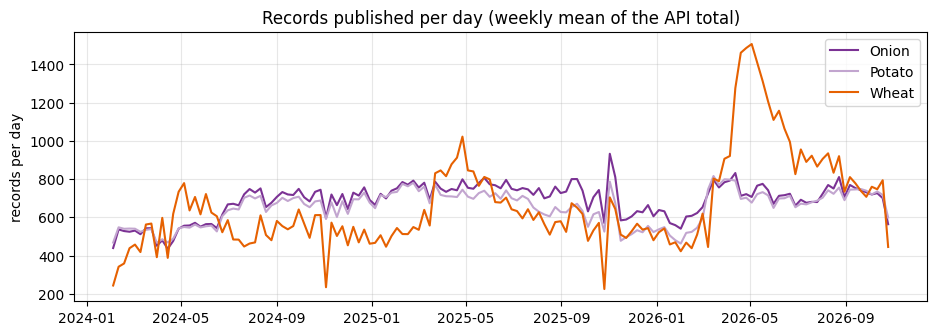

In [4]:
days = pd.read_csv(C / "crop_day_manifest.csv", parse_dates=["date"])
print(len(days), "crop-days,", days.status.value_counts().to_dict(), "|", days.date.min().date(), "→", days.date.max().date())
fig, ax = plt.subplots(figsize=(11, 3.5))
for crop, g in days.groupby("commodity"):
    w = g.set_index("date").api_total.resample("W").mean()
    ax.plot(w.index, w, label=crop, color=COLORS[crop])
ax.set(title="Records published per day (weekly mean of the API total)", ylabel="records per day"); ax.legend()
plt.show()

## 3. From raw records to usable targets

Each stage applies a documented rule; values are flagged, not repaired. Excluded records are kept with their reason.

In [5]:
sc = pd.read_csv(C / "dataset_v1_1/stage_counts.csv")
sc["count"] = sc.records.fillna(sc.usable)
tbl = sc.pivot_table(index="stage", columns="crop", values="count", sort=False).astype(int)
tbl

crop,Onion,Potato,Wheat
stage,,,
1_raw,683604,647268,659439
2_anomaly_policy,673264,644200,600587
3_r09,671551,643572,600400
4_5_identity_dedup,670141,642144,599349
6_grade_faq_only,398071,414119,480876
6_grade_faq_local,594115,567112,503908
6_grade_pooled,668147,640034,598016


In [6]:
rep = json.loads((C / "dataset_v1_1/build_report.json").read_text())
ex = pd.Series(rep["exclusions_by_reason"]["price_anomaly"]).rename("records").rename_axis("crop|reason").reset_index()
ex[["crop", "reason"]] = ex["crop|reason"].str.split("|", expand=True)
ex.pivot_table(index="reason", columns="crop", values="records", fill_value=0).astype(int)

crop,Onion,Potato,Wheat
reason,,,
key_conflict,9764,2967,52488
min_gt_max,4,1,0
modal_outside_range,571,80,6364
type_variant_duplicate,1,20,0


**Reading the table.** `key_conflict` (the same market, day and grade reported with different prices) dominates for Wheat: those records are excluded from targets rather than averaged. The Madhya Pradesh Wheat *modal outside [min, max]* pattern began at the source in December 2023 (`Data_Source_Review.md` §6.2).

## 4. Market identity

AGMARKNET renamed many markets when it relaunched. A rename was merged only after review; matching prices alone never establish identity.

In [7]:
m = pd.read_csv(C / "decisions_v1/mapping_decisions.csv", usecols=["decision"])
m.decision.value_counts().rename("market pairs").to_frame()

,market pairs
decision,
separate_pending_review,1053
separate_not_mapped,605
approved_candidate_experiment,440
separate_unresolved,81
separate_rejected,14


## 5. Coverage for forecasting

The weekly model table has one row per series × origin week × horizon. A row is **evaluated** only if the series has enough usable history at the origin (`eligible_d41`). The split is by the Sunday of the target week.

In [8]:
cov = pd.read_csv(C / "experiment_design_v1_1/coverage_by_period.csv")
cov[(cov.design == "faq_only") & (cov.horizon == 1)].set_index(["crop", "period"])[
    ["rows", "markets", "states", "target_weeks", "top5_state_share_pct"]]

rows  markets  states  target_weeks  top5_state_share_pct
crop   period                                                                
Onion  test         1048       72       8            16                  88.8
       train       10289      399      18            46                  81.2
       validation   1976      130      10            26                  82.5
Potato test         1137       82      11            16                  88.2
       train       10703      443      20            46                  79.0
       validation   2079      149      12            26                  87.3
Wheat  test         2591      177       5            16                 100.0
       train        5088      259       8            45                  94.9
       validation   3331      177       5            26                 100.0

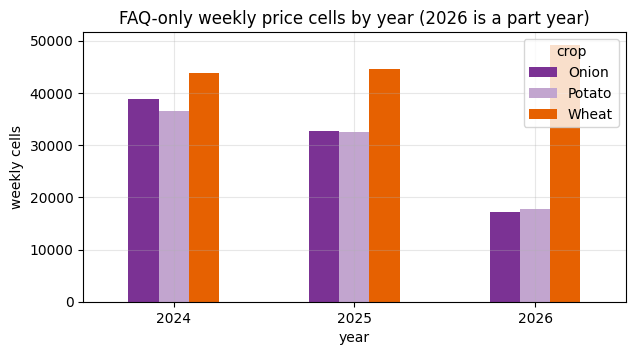

In [9]:
cy = pd.read_csv(C / "dataset_v1_1/coverage_by_design_crop_year.csv")
p = cy[cy.design == "faq_only"].pivot(index="year", columns="crop", values="weekly_cells")
ax = p.plot.bar(figsize=(7, 3.5), color=[COLORS[c] for c in p.columns], rot=0,
                title="FAQ-only weekly price cells by year (2026 is a part year)")
ax.set_ylabel("weekly cells"); plt.show()

## Limitations

- **Short history:** about 2.7 years, so seasonal baselines see roughly two seasons.
- **Concentration:** a few states hold most evaluated rows (Wheat: 5 states).
- **Identity:** 1,053 medium-confidence renames stay unmerged pending review, which splits some series.
- **No arrivals or weather** for this period; the candidate experiments are price-only (except the separately approved weather test in Extension 2).